## Week 4 Worksheet 10/1/26
#### ALK

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import pandas as pd
from numpy import sin, cos, pi, sqrt, exp, newaxis, acos, round

### Question 2

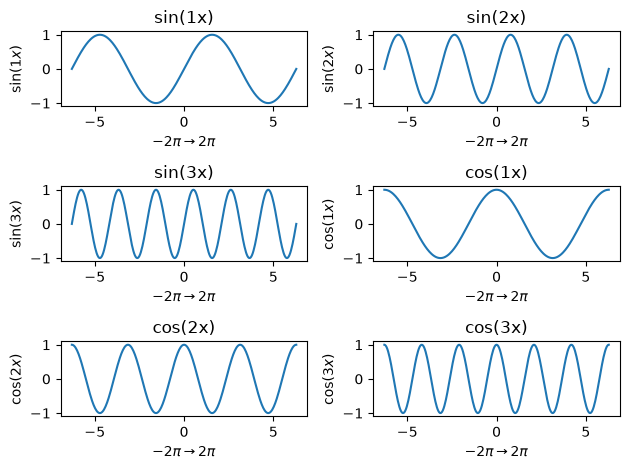

In [93]:
# plotting sin and cos for 3 different frequencies

xs = np.linspace(-2*pi, 2*pi, 300)

for i in range(1, 4):
    plt.subplot(320 + i)
    plt.plot(xs, sin(xs * i))
    plt.title(f'sin({i}x)')
    plt.xlabel('$-2\\pi \\to 2\\pi$')
    plt.ylabel(f'$\\sin({i}x)$')

    plt.subplot(320 + i + 3)
    plt.plot(xs, cos(xs * i))
    plt.title(f'cos({i}x)')
    plt.xlabel('$-2\\pi \\to 2\\pi$')
    plt.ylabel(f'$\\cos({i}x)$')

# plt.subplots_adjust(hspace=0.5, wspace=0.5)
plt.tight_layout()
plt.show()

### Question 4

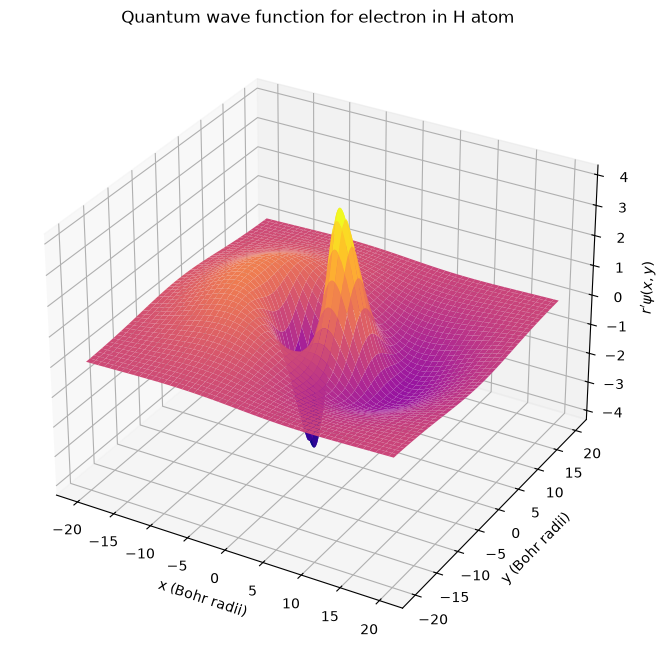

In [4]:
xs = np.linspace(-20, 20, 300)
ys = np.linspace(-20, 20, 300)[:,newaxis] # changes ys to a column vector

def wave_func(x, y):
    '''describes the wave function of a hydrogen atom for x, y, and returns psi(x, y)'''

    psi = x * (6 - sqrt(x**2 + y**2)) * exp(-sqrt(x**2 + y**2)/3)
    return psi

# make the surface plot
plt.figure(figsize=(10,8))

ax = plt.axes(projection='3d')
ax.plot_surface(xs,ys,wave_func(xs, ys),cmap=cm.plasma)
ax.set_xlabel('x (Bohr radii)')
ax.set_ylabel('y (Bohr radii)')
ax.set_zlabel('$r\'\\psi(x,y)$')
ax.set_title('Quantum wave function for electron in H atom')
plt.show()

### Question 5

Text(0, 0.5, 'y (Bohr radii)')

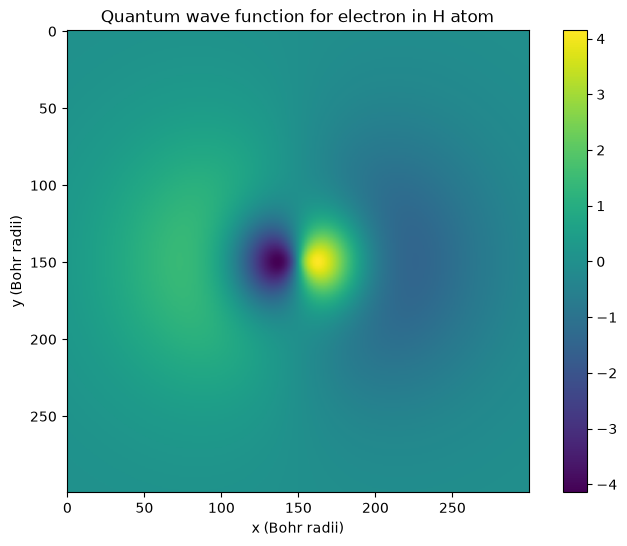

In [5]:
plt.figure(figsize=(9,6))
plt.imshow(wave_func(xs, ys))
plt.colorbar()
plt.title('Quantum wave function for electron in H atom')
plt.xlabel('x (Bohr radii)')
plt.ylabel('y (Bohr radii)')

### Question 6

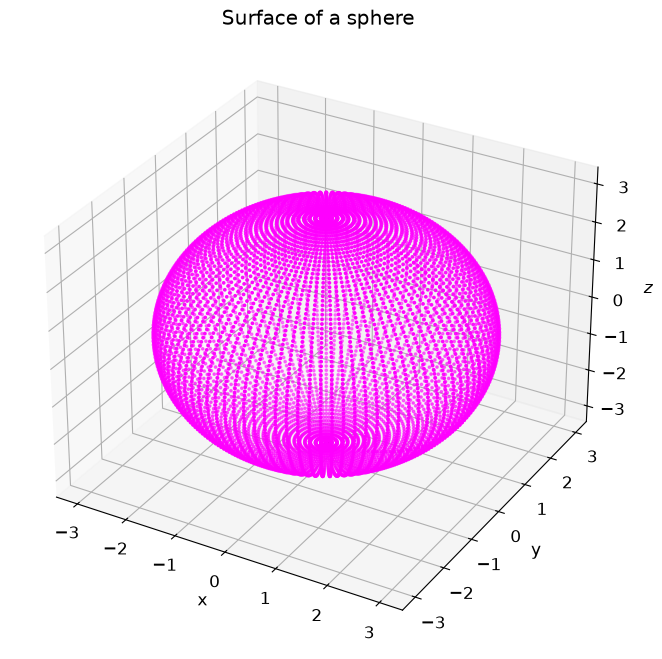

In [94]:
r = 3
xlist = []
ylist = []
zlist = []
nn = 100

for theta in np.linspace(0, pi, nn):
    for phi in np.linspace(0, 2 * pi, nn):
        xlist.append(r * sin(theta) * cos(phi))
        ylist.append(r * sin(theta) * sin(phi))
        zlist.append(r * cos(theta))

# make the surface plot
plt.figure(figsize=(10,8))
plt.rc('font', size = 12)
ax = plt.axes(projection='3d')
ax.scatter(xlist, ylist, zlist, color = 'magenta', s = 3)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('$z$')
ax.set_title('Surface of a sphere')
plt.show()

### Question 7

In [7]:
class Particle:
    """Particle in 2D, position (default x and y are zero).
    """
    def __init__(self,x=0.0,y=0.0):
        self.x = x
        self.y = y

#### 7(a)

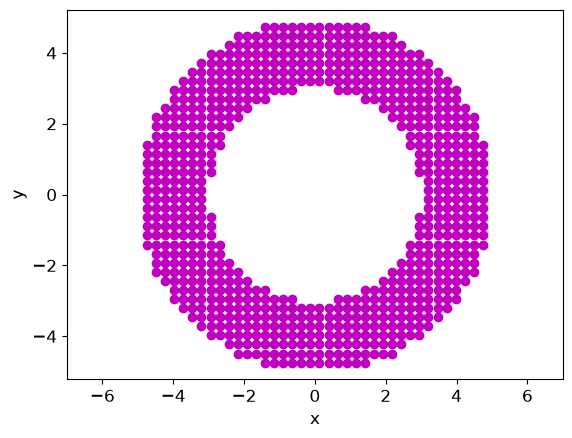

In [8]:
# Make particles on a grid, but only if they lie within a circle.
cparts = []
for x in np.linspace(-5,5,40):
    for y in np.linspace(-5,5,40):
        if sqrt(x**2 + y**2) <= 5 and sqrt(x**2 + y**2) >= 3:
            cparts.append(Particle(x,y))

# Plot the particle positions.
for p in cparts:
    plt.plot(p.x,p.y,'mo')

plt.xlabel('x')
plt.ylabel('y')

# The plot looks better with the x and y axis scaled equally.
ax = plt.gca()       # get current axes
ax.axis('equal')
plt.show()

#### 7(b)

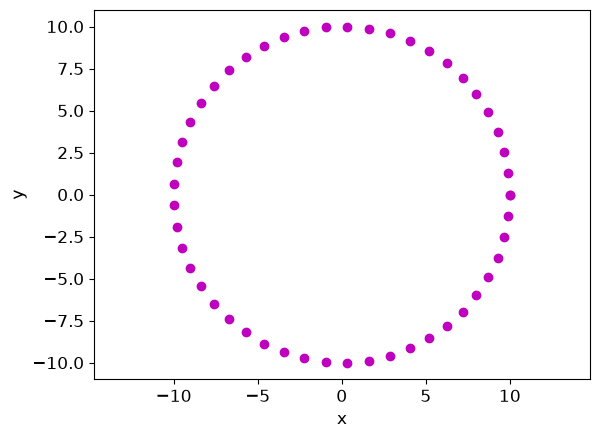

In [9]:
nn = 50
rr = 10

cparts = []

for theta in np.linspace(0, 2 * pi, nn):
    cparts.append(Particle(rr * cos(theta), rr * sin(theta)))

# Plot the particle positions.
for p in cparts:
    plt.plot(p.x,p.y,'mo')

plt.xlabel('x')
plt.ylabel('y')

# The plot looks better with the x and y axis scaled equally.
ax = plt.gca()       # get current axes
ax.axis('equal')
plt.show()

### Question 8

In [30]:
class RightTriangle:
    """Right triangle, defined by the legs. Default length is 1.
    """
    def __init__(self, l_1=1.0, l_2=1.0):
        self.l_1 = l_1
        self.l_2 = l_2

    def hyp(self):
        '''returns the hypotenuse of triangle'''
        return round(sqrt(self.l_1**2 + self.l_2**2), decimals = 5)

    def angle1(self):
        '''returns the angle by l_1'''
        return round(acos(self.l_1 / self.hyp()) * 180 / pi, decimals = 5)

    def angle2(self):
        '''returns the angle by l_2'''
        return round(acos(self.l_2 / self.hyp()) * 180 / pi, decimals = 5)

In [31]:
t = RightTriangle(1,sqrt(3))
print(t.hyp())
print(t.angle1())
print(t.angle2())

t2 = RightTriangle(1,1)
print(t2.hyp())
print(t2.angle1())
print(t2.angle2())

2.0
60.0
30.0
1.41421
44.99986
44.99986


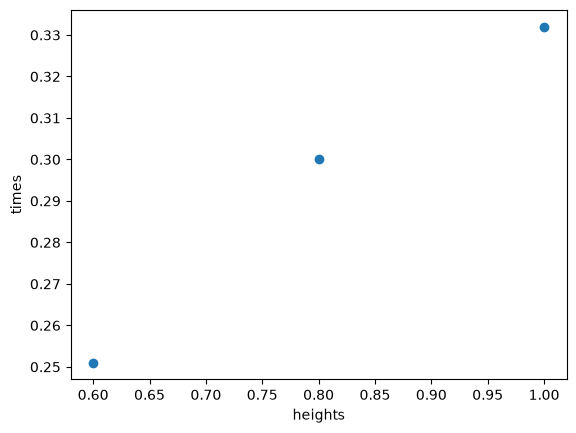

[1.  0.8 0.6]


In [ ]:
class Data:
    '''Data object has 2 lists of data with 2 headers'''
    def __init__(self, x_list, y_list):
        '''inits and saves the lists'''
        self.xs = x_list
        self.ys = y_list

    def plot(self):
        '''plots data with headers as ax labels'''
        plt.scatter(self.xs[1:], self.ys[1:])
        plt.xlabel(self.xs[0])
        plt.ylabel(self.ys[0])
        plt.show()

    def to_numpy(self, label):
        '''returns a numpy array of x or y if label matches x or y header'''
        if label == self.xs[0]:
            return np.array(self.xs[1:])
        elif label == self.ys[0]:
            return np.array(self.ys[1:])

falldata = Data(['heights', 1, 0.8, 0.6],
                ['times', 0.332, 0.3, 0.251])

falldata.plot()
print(falldata.to_numpy('heights'))

### Question 10, 11

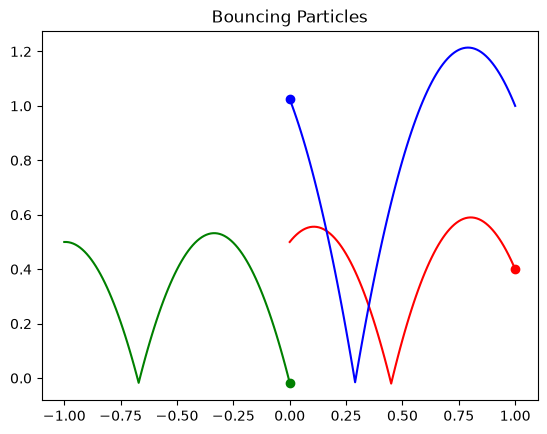

In [92]:
class Mass:
    '''creates a mass with (x, y) and velocities vx, vy'''
    def __init__(self, x, y, vx, vy):
        self.x = x
        self.y = y
        self.vx = vx
        self.vy = vy

        self.traj_x = [x]
        self.traj_y = [y]

    def step(self, dt):
        '''moves the mass forward in time by dt and adds the newest point to the trajectory'''
        if self.y == 0 or self.y < 0:
            self.vy = -self.vy
        
        self.x = self.x + self.vx * dt
        self.y = self.y + self.vy * dt
        self.vy = self.vy - 9.8 * dt

        self.traj_x.append(self.x)
        self.traj_y.append(self.y)

    def get_traj(self):
        '''returns the trajectories'''
        return self.traj_x, self.traj_y

m0 = Mass(0, 0.5, 1, 1)
m1 = Mass(1, 1, -1, 2)
m2 = Mass(-1, 0.5, 1, 0)
dt = 0.01

for i in range(100):
    m0.step(dt)
    m1.step(dt)
    m2.step(dt)

traj_x0, traj_y0 = m0.get_traj()
traj_x1, traj_y1 = m1.get_traj()
traj_x2, traj_y2 = m2.get_traj()

plt.plot(traj_x0, traj_y0, color = 'r')
plt.plot(m0.x, m0.y, 'ro')

plt.plot(traj_x1, traj_y1, color = 'b')
plt.plot(m1.x, m1.y, 'bo')

plt.plot(traj_x2, traj_y2, color = 'g')
plt.plot(m2.x, m2.y, 'go')

plt.title('Bouncing Particles')
plt.show()